# HD209458b: measured transit depths to atmospheric parameters
## 1. Problem
Recover an unresolved planet's atmosphere from **42 real measured transmission bands**, not from a synthetic image. Eight unknowns include atmospheric temperature, equilibrium metallicity, cloud pressure and scattering, geometry, and a shared error multiplier. There is **no physical atmospheric GT**. The original author v4 method is a reproducibility reference. The2019 paper describes an earlierrelease; we explicitly select v4 physics/discretization, not historical-figure equality.

## 2. Data
All42author-processed observations are retained:10STIS,28WFC3,4Spitzer. Authorprocessing adds60ppm toSTIS and combines Spitzer radiusratios using1/sigmaweights; both conventions remain unchanged. Independent thermochemical,opacity,collision,stellar tables are calibration, not estimates of this planet. C/O=.53 isfixed; only its exact neighboring interpolationnodes are retained.

Observation bands: 42 public calibration arrays: 16 all data retained


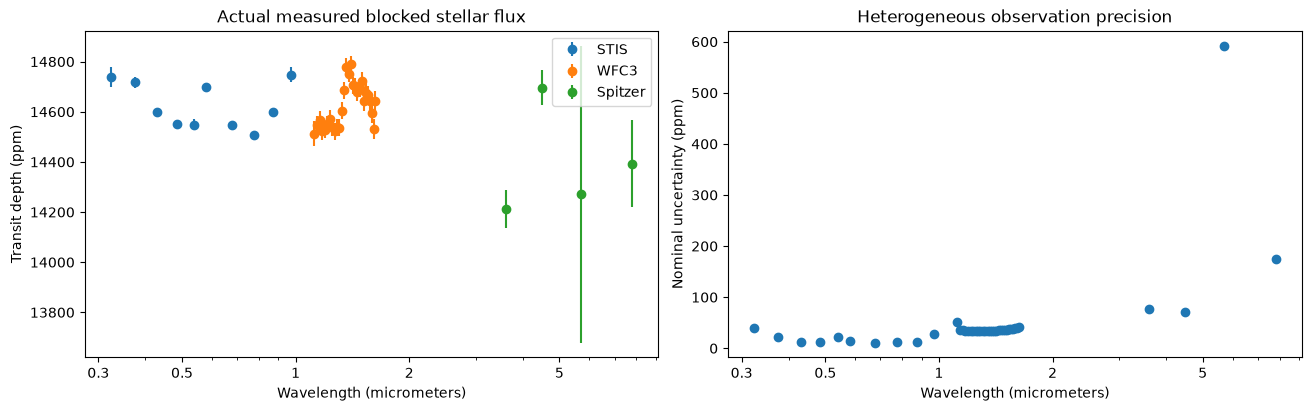

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator,NullFormatter,FuncFormatter
def clean_wave_ticks(axis):
 axis.xaxis.set_major_locator(FixedLocator([.3,.5,1,2,5,10]))
 axis.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x:g}'))
 axis.xaxis.set_minor_formatter(NullFormatter())
ROOT=Path.cwd() if (Path.cwd()/'src').is_dir() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,PARAMETERS
from src.physics_model import TransmissionModel
from src.solvers import reconstruct,GUESS,log_probability
from src.visualization import spectra,traces,corner,LABELS,UNITS
raw=load_observations('data/raw_data.npz');model=TransmissionModel(raw)
original=dict(np.load('notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False))
print('Observation bands:',len(raw['transit_depth']),'public calibration arrays:',len(raw),'all data retained')
fig,ax=plt.subplots(1,2,figsize=(13,4),layout='constrained')
centers=raw['wavelength_bins'].mean(1)*1e6
for start,end,label in [(0,10,'STIS'),(10,38,'WFC3'),(38,42,'Spitzer')]:
 ax[0].errorbar(centers[start:end],raw['transit_depth'][start:end]*1e6,yerr=raw['uncertainty'][start:end]*1e6,fmt='o',label=label)
ax[0].set(xscale='log',xlabel='Wavelength (micrometers)',ylabel='Transit depth (ppm)',title='Actual measured blocked stellar flux');ax[0].legend()
ax[1].plot(centers,raw['uncertainty']*1e6,'o');ax[1].set(xscale='log',xlabel='Wavelength (micrometers)',ylabel='Nominal uncertainty (ppm)',title='Heterogeneous observation precision')
for a in ax:clean_wave_ticks(a)
plt.show()

## 3. Physics
Spherical hydrostatic balance supplies radius as a function of pressure. Equilibrium chemistry sets number mixing ratios. Gas absorption, enhanced Rayleigh scattering and collision-induced absorption give extinction alpha [1/m]. Chord integration yields dimensionless optical depth tau. An opaque cloud blocks deeper shells. The blocked stellar flux is

$$
D(\lambda)=[r_c^2+2\int_{r_c}^{r_t}(1-\exp[-\tau(\lambda,b)])b\,\mathrm{d}b]/R_s^2.
$$

Here wavelength is lambda, impact radius is b, cloud/base radius is r-c, atmosphere top radius is r-t and stellar radius is R-s, all lengths in m. The instrument band prediction is the stellar-weighted average of this spectrum on the actual band interval. The isothermal atmospheric temperature is in K, metallicity and cloud pressure use base10logs, and the planetary radius is defined at1bar. Optical depth and spectral weighting are implemented locally.

## 4. Method
We explicitly implement the original hydrostatic and opacity discretization and an affine-invariant red/blue stretch sampler, including normalized Gaussian likelihood and ancillary stellar-radius/planet-mass constraints. All **50walkers ×1000transitions** run actively below. All50000samples are retained, matching the author example; no burn discard or convergence claim is introduced. The error multiplier is estimated jointly, including its Gaussian log-normalization term. Its value near2.4is an inference result, not a posthoc change to observed errors.

The following cell takes approximately24minutes on the validated single-thread CPU. It computes from raw data through every selected inverse transition; archived arrays are used only for labeled comparisons. A long timeout accommodates the scientific protocol.

In [2]:
start=time.perf_counter()
fresh,diagnostics=reconstruct(model,seed=20261028,steps=1000,progress=lambda n,p:print('transition',n,'maximum log posterior',p,flush=True) if n%100==0 else None)
elapsed=time.perf_counter()-start
np.savez_compressed('output/reconstruction.npz',**fresh)
spec=importlib.util.spec_from_file_location('physical_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,status=judge.evaluate(ROOT/'output/reconstruction.npz')
print('FRESH FULL RETRIEVAL:',elapsed,'seconds; chain',diagnostics['chain'].shape,'Judge:',report['status']);print(json.dumps(report,indent=2));assert status==0
np.savez_compressed('notebooks/reference_outputs/notebook_measurements.npz',**fresh,**diagnostics,runtime_seconds=np.array(elapsed),seed=np.array(20261028))

transition 100 maximum log posterior 255.3932184589718
transition 200 maximum log posterior 255.60927447848945
transition 300 maximum log posterior 255.3378755100973
transition 400 maximum log posterior 254.68732169196966
transition 500 maximum log posterior 254.78097755214407
transition 600 maximum log posterior 254.53130785706549
transition 700 maximum log posterior 255.53322408288926
transition 800 maximum log posterior 254.51594230567397
transition 900 maximum log posterior 255.22677805071737
transition 1000 maximum log posterior 255.130366652378
FRESH FULL RETRIEVAL: 1219.1013824000256 seconds; chain (50, 1000, 8) Judge: pass
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "median_standardized_max": 0.0,
    "best_standardized_max": 0.0,
    "spectrum_max_ppm": 0.0,
    "unscaled_chi2": 250.84180753333615,
    "log_posterior_min": 256.249041852333,
    "spectrum_consistency_ppm": 0.0
  },
  "thresholds": {
    "median_standardized_max": {
      "comparison": "<=",
     

## 5. Results
### All measured bands and posterior predictive structure
Every fresh model below uses locally computed parameters. The original result is explicitly identified. The red band summarizes physical model predictions from32deterministically spaced samples of the full fresh finite chain; it does not include measurement noise and is not a convergence-certified credible interval.

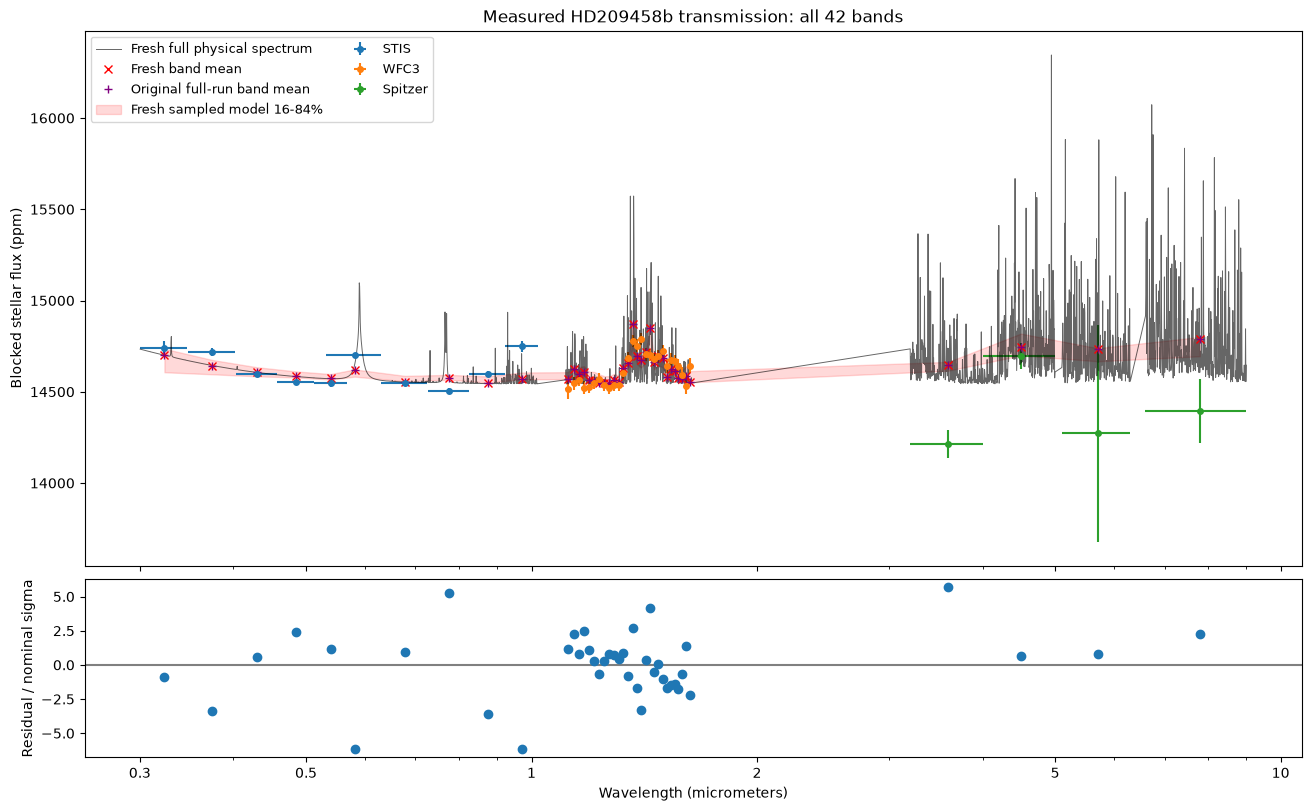

Parameter | original median | fresh median | standardized difference
Rs 830181287.1292121 830181287.1292121 0.0
Mp 1.3849501200478866e+27 1.3849501200478866e+27 0.0
Rp 97741560.67301765 97741560.67301765 0.0
T 1125.0697048938287 1125.0697048938287 0.0
log_scatt_factor 0.7975795546695377 0.7975795546695377 0.0
logZ 0.8698309758192583 0.8698309758192583 0.0
log_cloudtop_P 2.1451482151215577 2.1451482151215577 0.0
error_multiple 2.75348549739816 2.75348549739816 0.0
Finite-chain 16/50/84 percentiles (no convergence claim); and best sampled vector:
Stellar radius (solar) original [1.17257861 1.19330356 1.2127939 ] fresh [1.17257861 1.19330356 1.2127939 ] fresh best 1.1876255058832756
Planet mass (Jupiter) original [0.69339717 0.72961617 0.7712951 ] fresh [0.69339717 0.72961617 0.7712951 ] fresh best 0.7378305925561812
Reference radius (Jupiter) original [1.34207192 1.3671678  1.3945836 ] fresh [1.34207192 1.3671678  1.3945836 ] fresh best 1.3667470013602052
Temperature (K) original [ 959.6

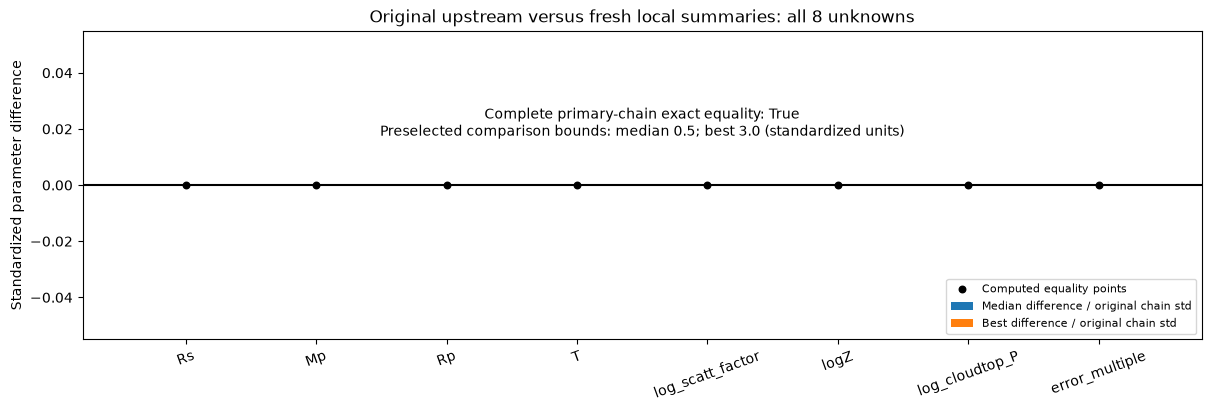

In [3]:
best=fresh['best_fit'][0];chain=diagnostics['chain'];logp=diagnostics['log_probability']
depth,physical=model.forward(best,full_output=True)
sampled=chain.reshape(-1,8);prediction=np.array([model.forward(p) for p in sampled[np.linspace(0,len(sampled)-1,32,dtype=int)]])
spectrum_figure=spectra(raw,depth,original['transit_depth'][0],physical['unbinned_wavelengths'],physical['unbinned_depths'],prediction)
for a in spectrum_figure.axes:clean_wave_ticks(a)
plt.show()
sigma=original['parameter_sigma'][0]
print('Parameter | original median | fresh median | standardized difference')
for i,label in enumerate(PARAMETERS):print(label,original['reconstruction'][0,i],fresh['reconstruction'][0,i],(fresh['reconstruction'][0,i]-original['reconstruction'][0,i])/sigma[i])
# Preserve the original BestFit.txt scientific summary, in labeled display units.
original_quantiles=np.percentile(original['chain'][0].reshape(-1,8),[16,50,84],axis=0)/UNITS
fresh_quantiles=np.percentile(sampled,[16,50,84],axis=0)/UNITS
print('Finite-chain 16/50/84 percentiles (no convergence claim); and best sampled vector:')
for j,label in enumerate(LABELS):
 print(label,'original',original_quantiles[:,j],'fresh',fresh_quantiles[:,j],'fresh best',best[j]/UNITS[j])
fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
ax.bar(np.arange(8)-.2,(fresh['reconstruction'][0]-original['reconstruction'][0])/sigma,.4,label='Median difference / original chain std')
ax.bar(np.arange(8)+.2,(best-original['best_fit'][0])/sigma,.4,label='Best difference / original chain std');ax.axhline(0,color='black');ax.set_xticks(range(8),PARAMETERS,rotation=20);ax.set(ylabel='Standardized parameter difference',title='Original upstream versus fresh local summaries: all 8 unknowns');ax.scatter(np.arange(8),(fresh['reconstruction'][0]-original['reconstruction'][0])/sigma,color='black',s=22,zorder=5,label='Computed equality points')
exact=np.array_equal(chain,original['chain'][0])
ax.text(.5,.70,f'Complete primary-chain exact equality: {exact}\nPreselected comparison bounds: median 0.5; best 3.0 (standardized units)',transform=ax.transAxes,ha='center',va='center',fontsize=10)
ax.legend(loc='lower right',fontsize=8);plt.show()

### Ensemble diagnostics and full eight-parameter comparison
The original supplied example includes a best-fit spectrum and an8parametercornerplot; both scientific comparison groups are retained here. We add complete50walkertrajectories, per-step logposterior and per-walker acceptance. Finite chains, shared walkers and initialization can affect summaries. We report sensitivity through an independently run original secondseed and never call50000correlatedsamples50000independentmeasurements.

Corner axes use solar radii, Jupiter masses and radii, kelvin, base10 logarithms and dimensionless error scale. Exact original/fresh distributions overlap. Pure display polish was separately re-executed from this notebook's identified complete native-run measurement; no additional complete MCMC execution is claimed.

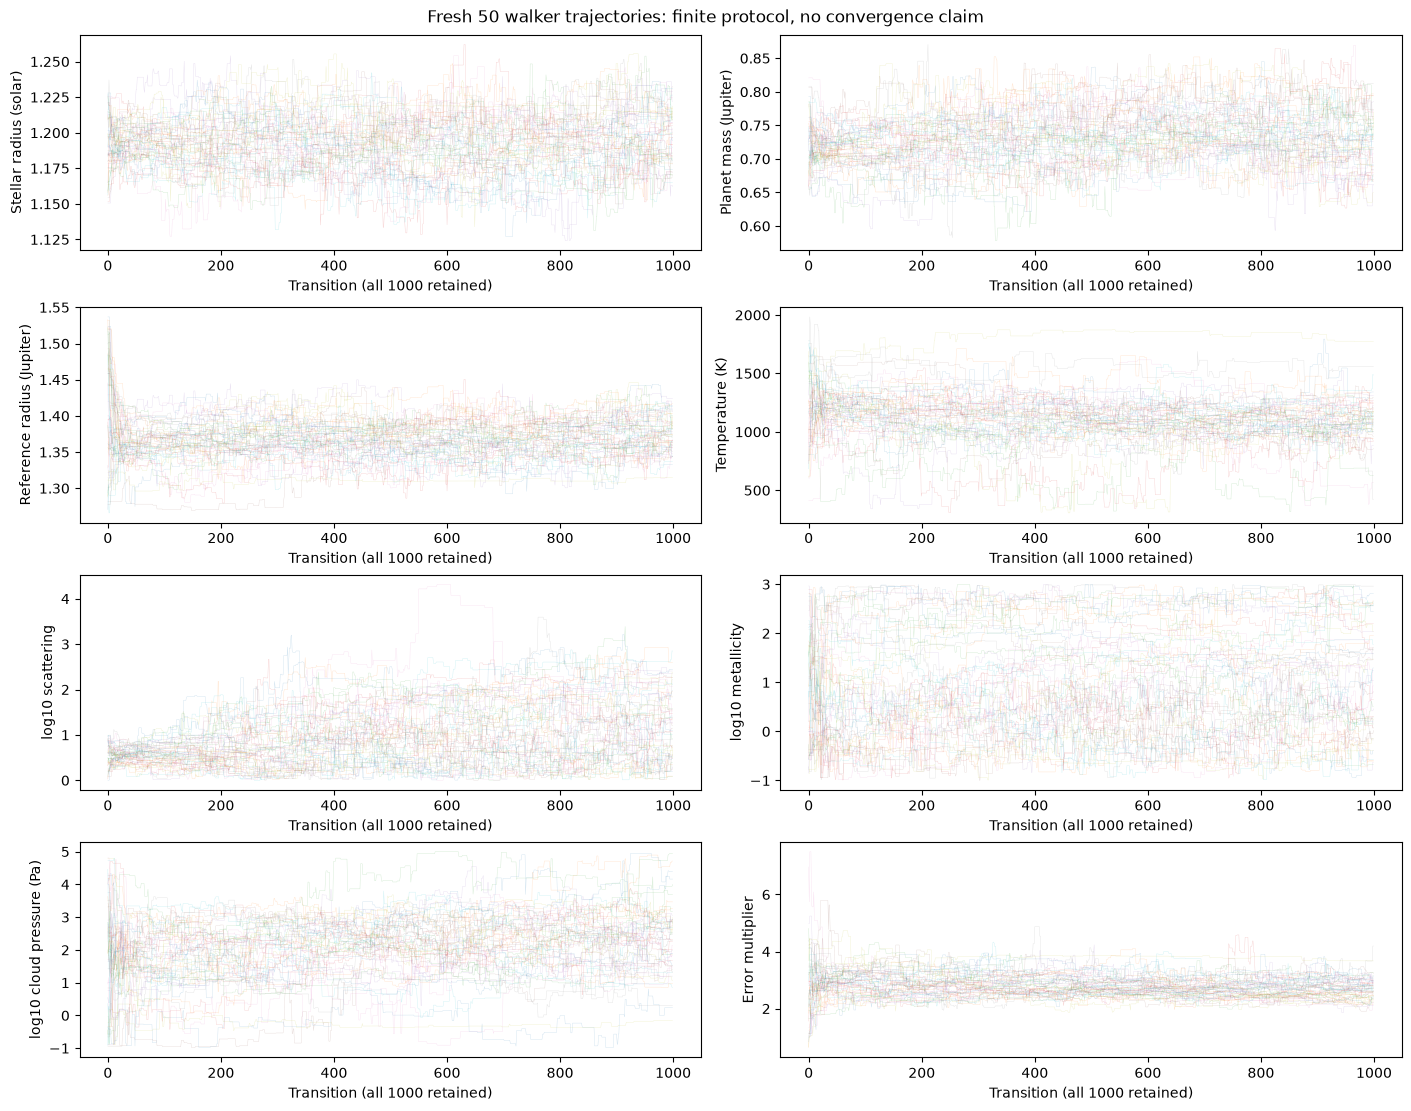

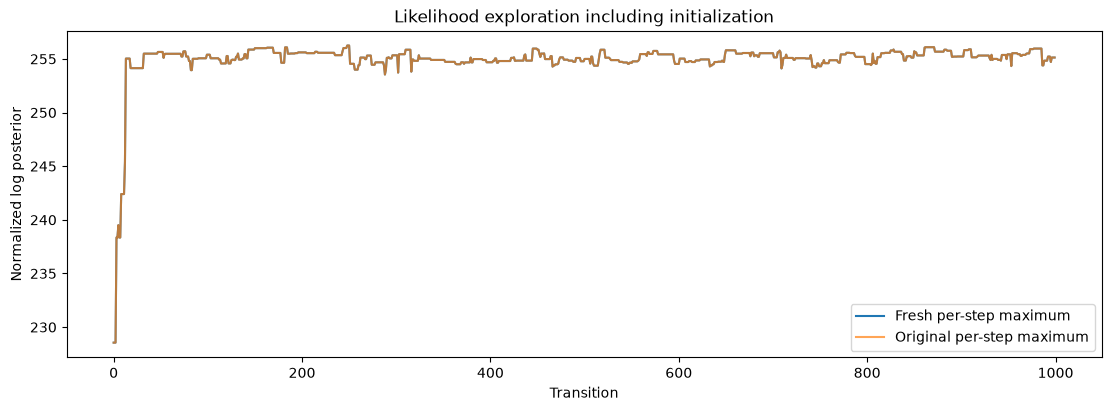

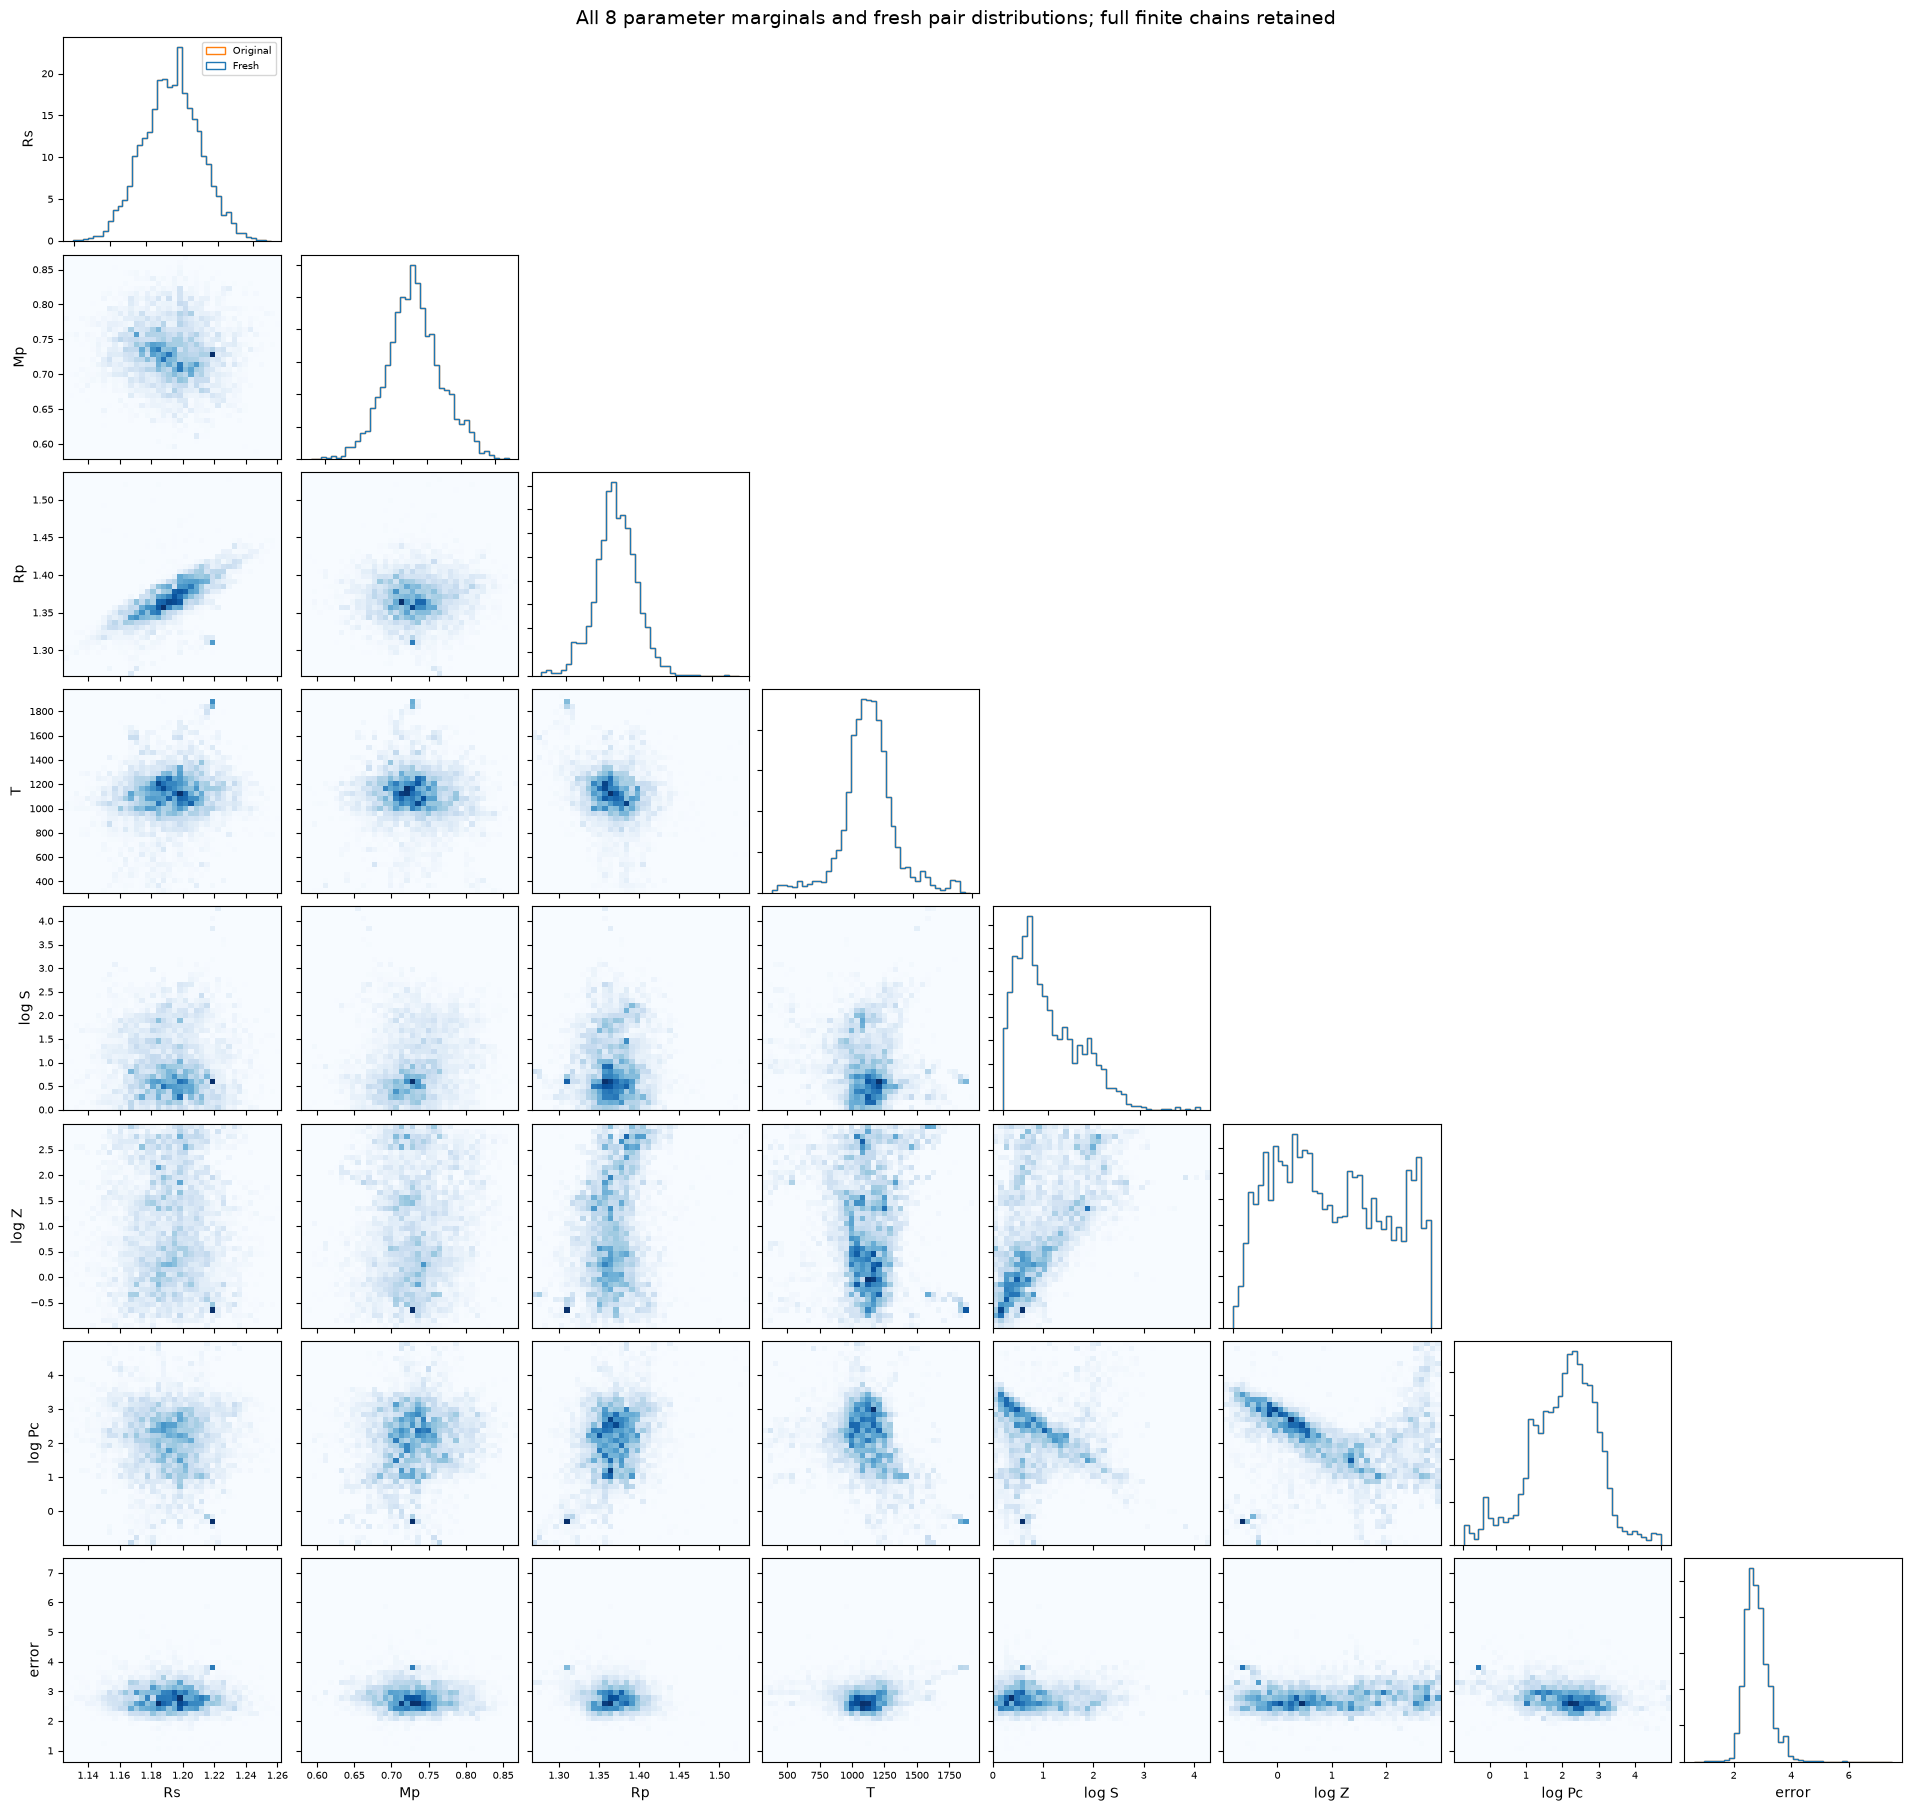

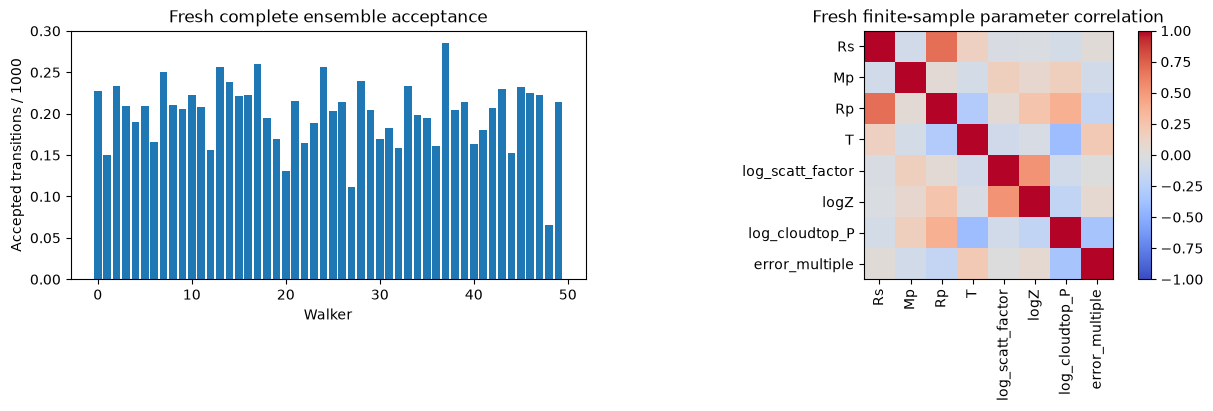

In [4]:
traces(chain,logp,original['log_probability'][0]);plt.show()
corner(chain,original['chain'][0]);plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
ax[0].bar(np.arange(50),diagnostics['acceptance_fraction']);ax[0].set(xlabel='Walker',ylabel='Accepted transitions / 1000',title='Fresh complete ensemble acceptance')
corr=np.corrcoef(sampled.T);im=ax[1].imshow(corr,vmin=-1,vmax=1,cmap='coolwarm');ax[1].set_xticks(range(8),PARAMETERS,rotation=90);ax[1].set_yticks(range(8),PARAMETERS);ax[1].set_title('Fresh finite-sample parameter correlation');fig.colorbar(im,ax=ax[1]);plt.show()

### Physical structure and opacity experiments
These are fresh forward evaluations at the recovered best vector, with one opacity component omitted at a time. They diagnose spectral dependence; they are **not** new atmospheric retrievals and do not replace the complete selected model.

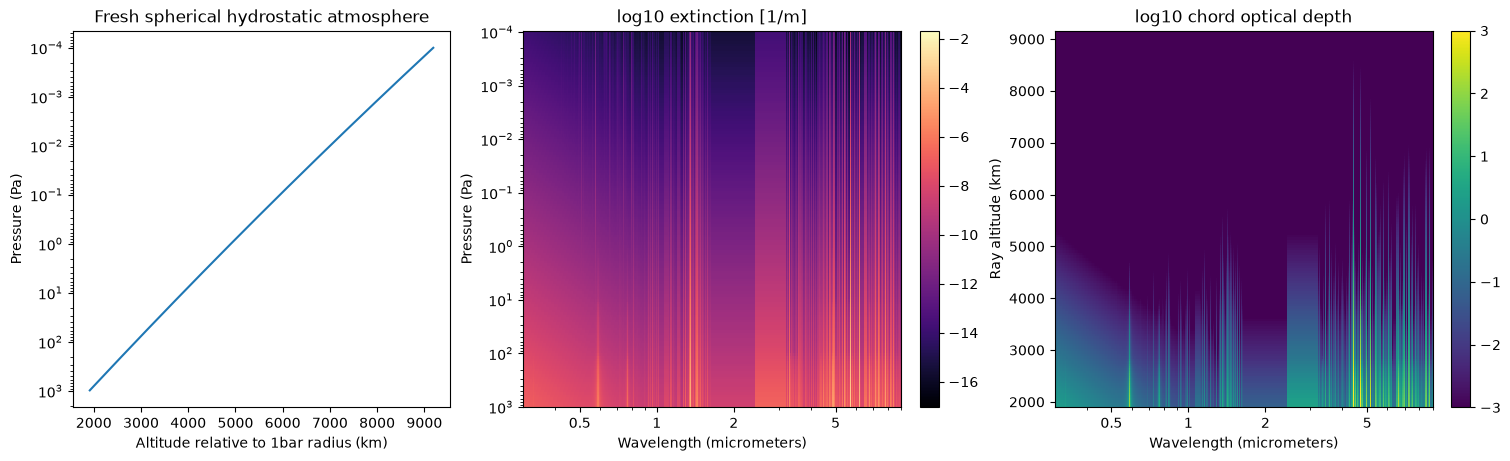

[
  {
    "model": "Full selected model",
    "unscaled_chi2": 250.84180753333615,
    "rms_depth_change_ppm": 0.0
  },
  {
    "model": "Gas absorption omitted",
    "unscaled_chi2": 542.657663269936,
    "rms_depth_change_ppm": 114.54671164572554
  },
  {
    "model": "Rayleigh omitted",
    "unscaled_chi2": 354.69749788534114,
    "rms_depth_change_ppm": 31.877266874175564
  },
  {
    "model": "Collision absorption omitted",
    "unscaled_chi2": 250.80220984746796,
    "rms_depth_change_ppm": 0.19375204645914262
  }
]


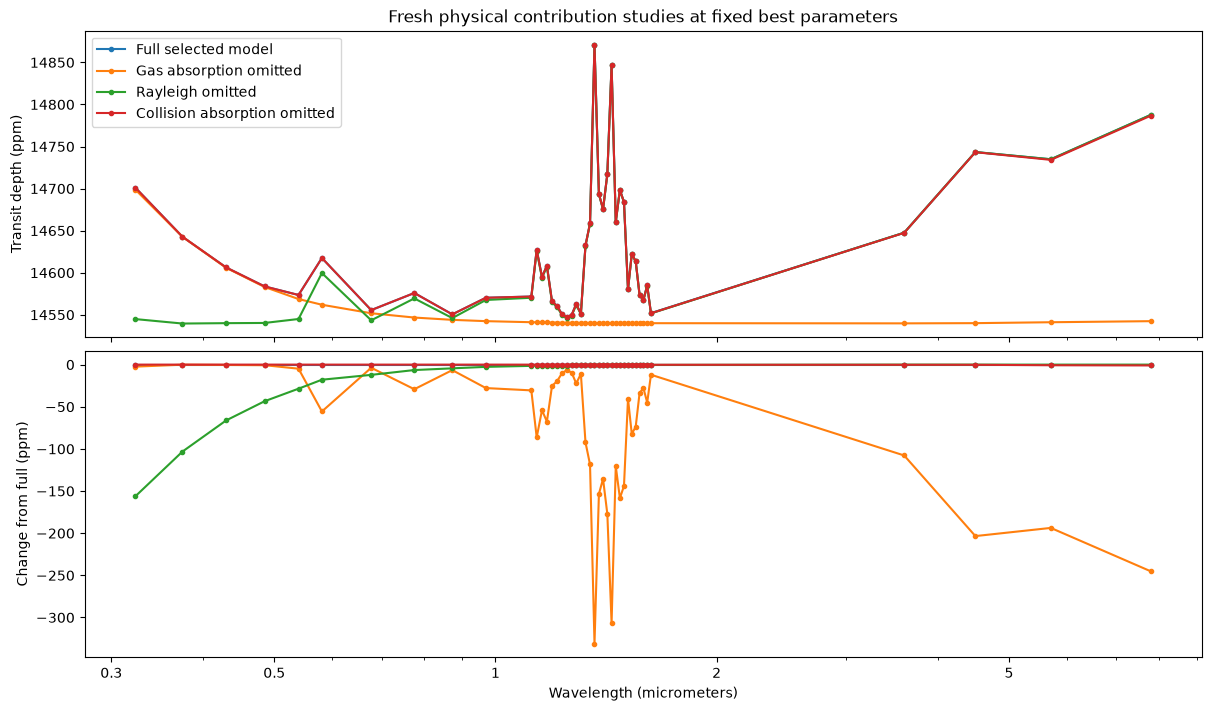

In [4]:
fig,ax=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
altitude=(physical['radii']-best[2])/1000
ax[0].plot(altitude,physical['P_profile']);ax[0].set(yscale='log',xlabel='Altitude relative to 1bar radius (km)',ylabel='Pressure (Pa)',title='Fresh spherical hydrostatic atmosphere');ax[0].invert_yaxis()
im=ax[1].pcolormesh(physical['unbinned_wavelengths']*1e6,physical['P_profile'],np.log10(np.maximum(physical['absorption_coeff_atm'],1e-99)),shading='auto',cmap='magma');ax[1].set(xscale='log',yscale='log',xlabel='Wavelength (micrometers)',ylabel='Pressure (Pa)',title='log10 extinction [1/m]');ax[1].invert_yaxis();fig.colorbar(im,ax=ax[1])
im=ax[2].pcolormesh(physical['unbinned_wavelengths']*1e6,altitude[1:],np.log10(np.maximum(physical['tau_los'].T,1e-20)),shading='auto',vmin=-3,vmax=3,cmap='viridis');ax[2].set(xscale='log',xlabel='Wavelength (micrometers)',ylabel='Ray altitude (km)',title='log10 chord optical depth');fig.colorbar(im,ax=ax[2])
for a in ax[1:]:clean_wave_ticks(a)
plt.show()
fig,ax=plt.subplots(2,1,figsize=(12,7),sharex=True,layout='constrained')
ablation=[]
for label,options in [('Full selected model',{}),('Gas absorption omitted',{'gas':False}),('Rayleigh omitted',{'rayleigh':False}),('Collision absorption omitted',{'collision':False})]:
 d=model.forward(best,**options);ax[0].plot(centers,d*1e6,'o-',label=label,ms=3);ax[1].plot(centers,(d-depth)*1e6,'o-',label=label,ms=3)
 ablation.append(dict(model=label,unscaled_chi2=float(np.sum(((d-raw['transit_depth'])/raw['uncertainty'])**2)),rms_depth_change_ppm=float(np.sqrt(np.mean((d-depth)**2))*1e6)))
ax[0].set(ylabel='Transit depth (ppm)',title='Fresh physical contribution studies at fixed best parameters');ax[0].legend();ax[1].set(xscale='log',xlabel='Wavelength (micrometers)',ylabel='Change from full (ppm)');print(json.dumps(ablation,indent=2))
for a in ax:clean_wave_ticks(a)
plt.show()

### Observation mismatch and inferred error multiplier
Nominal and inferred-error residuals are both shown. This retains the cost of mismatched heterogeneous data instead of hiding it with reference parity. A fitted common errorfactor is a nuisance parameter with finite-sample uncertainty, not evidence that every instrument shares the same systematic mechanism.

The published method also identifies finite-resolution opacity sampling as a possible source of excess scatter. This common nuisance scale does not separate model discrepancy from observational systematics.

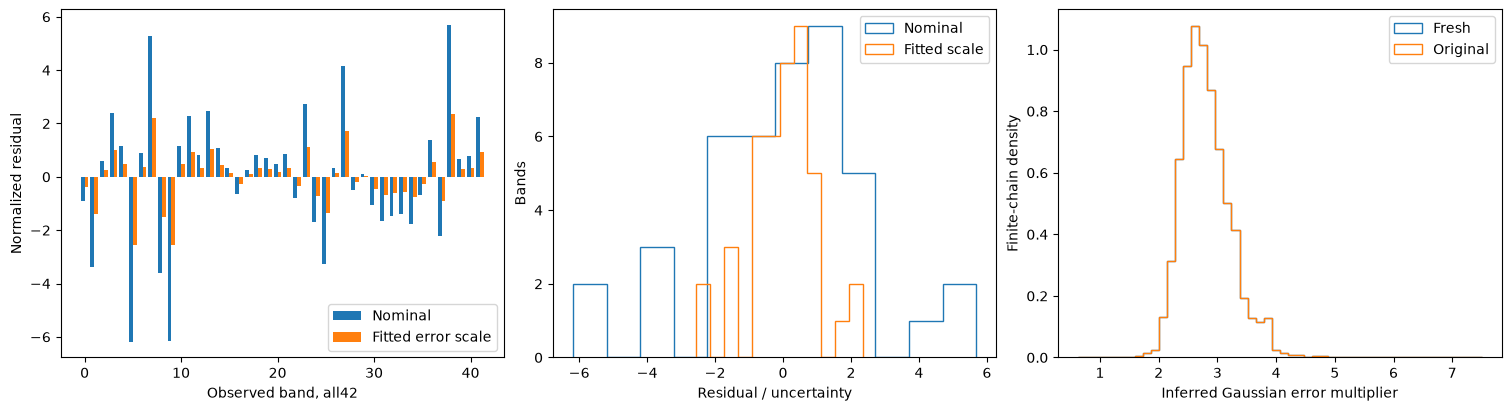

Nominal chi2 250.84180753333612 scaled chi2 43.3881886256198 best error scale 2.404441421702827 number of bands 42
Total active retrieval runtime 1219.1013824000256 s; 50x1000 protocol retained without burn discard


In [6]:
r=(depth-raw['transit_depth'])/raw['uncertainty'];scaled=r/best[7]
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
ax[0].bar(np.arange(42)-.2,r,.4,label='Nominal');ax[0].bar(np.arange(42)+.2,scaled,.4,label='Fitted error scale');ax[0].set(xlabel='Observed band, all42',ylabel='Normalized residual');ax[0].legend()
ax[1].hist(r,bins=12,histtype='step',label='Nominal');ax[1].hist(scaled,bins=12,histtype='step',label='Fitted scale');ax[1].set(xlabel='Residual / uncertainty',ylabel='Bands');ax[1].legend()
ax[2].hist(sampled[:,7],bins=50,density=True,histtype='step',label='Fresh');ax[2].hist(original['chain'][0].reshape(-1,8)[:,7],bins=50,density=True,histtype='step',label='Original');ax[2].set(xlabel='Inferred Gaussian error multiplier',ylabel='Finite-chain density');ax[2].legend();plt.show()
print('Nominal chi2',float(r@r),'scaled chi2',float(scaled@scaled),'best error scale',best[7],'number of bands',42)
print('Total active retrieval runtime',elapsed,'s; 50x1000 protocol retained without burn discard')

## 6. Conclusion
The fresh local inverse recovered all declared parameter summaries and a physical42bandtransmission spectrum from the complete real observed band set. Original-stage parity, independent original seed variation, parameter/spectrum contracts and the observation metrics have separate roles. **No true atmosphere is supplied.** Clouds, metallicity, scattering, radius and temperature can remain correlated; complete finite-chain diagnostics and the inferred common error scale constrain how strongly to interpret the estimates. Opacity ablations expose physical contributions but do not establish uniqueness. The original author processing conventions and v4discretization are preserved and disclosed.

References: Zhang etal2019arXiv1811.11761 (published physics/retrieval family); original authorv4fixedrevision in validation; realSTIS DOI10.1086/510111, WFC3arXiv1302.1141, SpitzerarXiv1504.05942. GPL3localatmosphericextraction; emceeMITstretch-update attribution in NOTICE.